Training Model 1: TF-IDF + Logistic Regression
Training & Inference Time: 0.11s
Logistic Regression Accuracy: 0.9704

              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115

Training Model 2: DistilBERT Transformer
Using device: cuda | Available GPUs: 2


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wrapping DistilBERT with nn.DataParallel across 2 GPUs...


Epoch 1/3:   0%|          | 0/70 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch 1/3 - Train Loss: 0.1692


Epoch 2/3 - Train Loss: 0.0309


Epoch 3/3 - Train Loss: 0.0216

Training & Inference Time: 83.06s
DistilBERT Accuracy: 0.9928

              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       966
        Spam       0.99      0.96      0.97       149

    accuracy                           0.99      1115
   macro avg       0.99      0.98      0.98      1115
weighted avg       0.99      0.99      0.99      1115



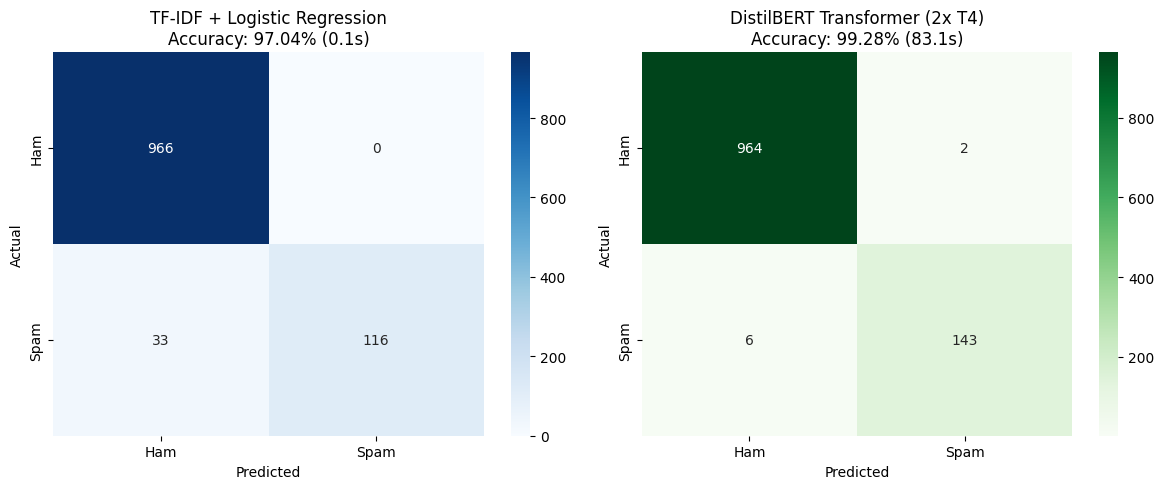

In [3]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, get_linear_schedule_with_warmup
from tqdm import tqdm

# ==========================================
# 1. Load & Clean SMS Dataset
# ==========================================
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label"] = df["label"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(
    df["message"].tolist(),
    df["label"].values,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

# ==========================================
# MODEL 1: TF-IDF + Logistic Regression (CPU)
# ==========================================
print("=" * 50)
print("Training Model 1: TF-IDF + Logistic Regression")
print("=" * 50)

start_lr = time.time()
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)
lr_preds = lr_model.predict(X_test_vec)
lr_time = time.time() - start_lr

lr_acc = accuracy_score(y_test, lr_preds)
print(f"Training & Inference Time: {lr_time:.2f}s")
print(f"Logistic Regression Accuracy: {lr_acc:.4f}\n")
print(classification_report(y_test, lr_preds, target_names=["Ham", "Spam"]))

# ==========================================
# MODEL 2: DistilBERT (Dual T4 GPU Ready)
# ==========================================
print("=" * 50)
print("Training Model 2: DistilBERT Transformer")
print("=" * 50)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
print(f"Using device: {device} | Available GPUs: {num_gpus}")

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
MAX_LEN = 128

train_encodings = tokenizer(X_train, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
test_encodings = tokenizer(X_test, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")

class SMSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# Scale batch size when 2 GPUs are active (32 per GPU -> 64 total)
batch_size = 32 * max(1, num_gpus)
train_loader = DataLoader(SMSDataset(train_encodings, y_train), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(SMSDataset(test_encodings, y_test), batch_size=64 * max(1, num_gpus), shuffle=False)

bert_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

# ---> ENABLE DUAL KAGGLE GPUs <---
if num_gpus > 1:
    print(f"Wrapping DistilBERT with nn.DataParallel across {num_gpus} GPUs...")
    bert_model = nn.DataParallel(bert_model)

bert_model.to(device)

EPOCHS = 3
optimizer = AdamW(bert_model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

start_bert = time.time()
for epoch in range(EPOCHS):
    bert_model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        
        # .mean() averages the loss vectors returned by each GPU in DataParallel
        loss = outputs.loss.mean()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{EPOCHS} - Train Loss: {total_loss / len(train_loader):.4f}")

# Evaluation
bert_model.eval()
bert_preds = []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        outputs = bert_model(input_ids, attention_mask=attention_mask)
        bert_preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())

bert_time = time.time() - start_bert
bert_acc = accuracy_score(y_test, bert_preds)
print(f"\nTraining & Inference Time: {bert_time:.2f}s")
print(f"DistilBERT Accuracy: {bert_acc:.4f}\n")
print(classification_report(y_test, bert_preds, target_names=["Ham", "Spam"]))

# ==========================================
# 3. Side-by-Side Confusion Matrices
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[0].set_title(f"TF-IDF + Logistic Regression\nAccuracy: {lr_acc:.2%} ({lr_time:.1f}s)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_bert = confusion_matrix(y_test, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[1].set_title(f"DistilBERT Transformer (2x T4)\nAccuracy: {bert_acc:.2%} ({bert_time:.1f}s)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Dataset Splits -> Train: 3900 | Val: 836 | Test: 836

Training Model 1: TF-IDF + SMOTE + Logistic Regression
Time: 0.14s
Overfitting Check -> Train Acc: 0.9913 | Val Acc: 0.9785 | Gap: 0.0128
Final Test Accuracy: 0.9833

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       724
        Spam       0.95      0.93      0.94       112

    accuracy                           0.98       836
   macro avg       0.97      0.96      0.96       836
weighted avg       0.98      0.98      0.98       836

Training Model 2: DistilBERT + Weighted CrossEntropyLoss
Using device: cuda | Available GPUs: 2


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wrapping DistilBERT with nn.DataParallel across 2 GPUs...


Epoch 1/4 | Train Loss: 0.2303 - Val Loss: 0.1093 | Train Acc: 0.9056 - Val Acc: 0.9809


Epoch 2/4 | Train Loss: 0.0599 - Val Loss: 0.0989 | Train Acc: 0.9877 - Val Acc: 0.9821


Epoch 3/4 | Train Loss: 0.0408 - Val Loss: 0.1088 | Train Acc: 0.9931 - Val Acc: 0.9868


Epoch 4/4 | Train Loss: 0.0302 - Val Loss: 0.1073 | Train Acc: 0.9951 - Val Acc: 0.9868

Total Training Time: 99.98s
Final DistilBERT Test Accuracy: 0.9940

              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       724
        Spam       0.99      0.96      0.98       112

    accuracy                           0.99       836
   macro avg       0.99      0.98      0.99       836
weighted avg       0.99      0.99      0.99       836



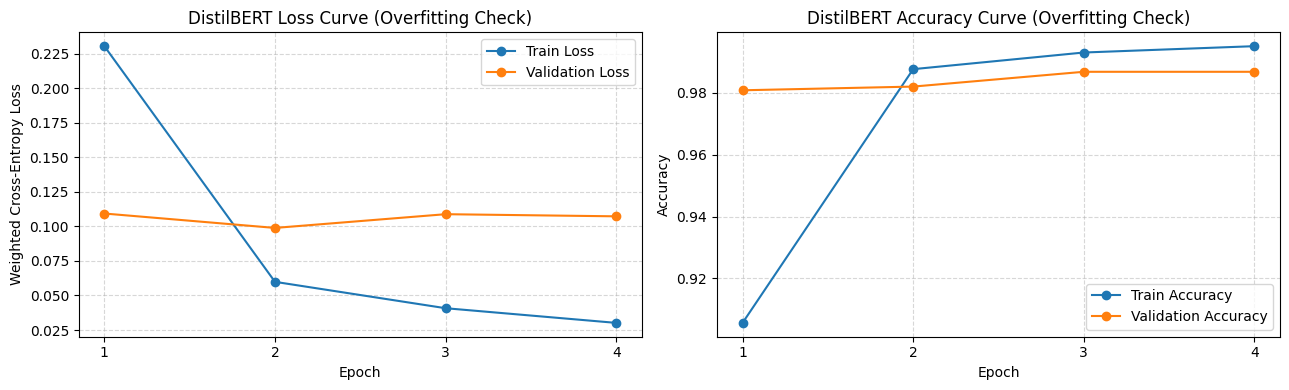

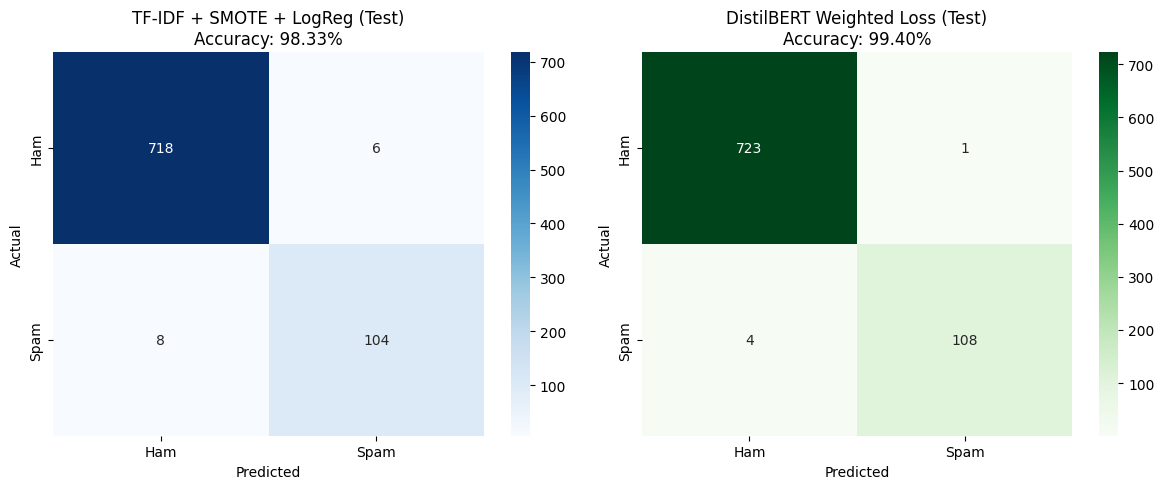

In [4]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, get_linear_schedule_with_warmup
from tqdm import tqdm

# ==========================================
# 1. Load & Clean SMS Dataset (Train / Val / Test Split)
# ==========================================
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label"] = df["label"].map({"ham": 0, "spam": 1})

# First split: 70% Train, 30% Temp (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    df["message"].tolist(),
    df["label"].values,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Second split: Split the 30% Temp equally into 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(f"Dataset Splits -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}\n")

# ==========================================
# MODEL 1: TF-IDF + SMOTE + Logistic Regression
# ==========================================
print("=" * 60)
print("Training Model 1: TF-IDF + SMOTE + Logistic Regression")
print("=" * 60)

start_lr = time.time()
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

# Apply SMOTE strictly on training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_vec, y_train)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_smote, y_train_smote)
lr_time = time.time() - start_lr

# Overfitting Check: Train vs Validation Accuracy
lr_train_acc = accuracy_score(y_train, lr_model.predict(X_train_vec))
lr_val_acc = accuracy_score(y_val, lr_model.predict(X_val_vec))
lr_test_preds = lr_model.predict(X_test_vec)
lr_test_acc = accuracy_score(y_test, lr_test_preds)

print(f"Time: {lr_time:.2f}s")
print(f"Overfitting Check -> Train Acc: {lr_train_acc:.4f} | Val Acc: {lr_val_acc:.4f} | Gap: {lr_train_acc - lr_val_acc:.4f}")
print(f"Final Test Accuracy: {lr_test_acc:.4f}\n")
print(classification_report(y_test, lr_test_preds, target_names=["Ham", "Spam"]))

# ==========================================
# MODEL 2: DistilBERT + Weighted Loss (2x T4 GPU)
# ==========================================
print("=" * 60)
print("Training Model 2: DistilBERT + Weighted CrossEntropyLoss")
print("=" * 60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
print(f"Using device: {device} | Available GPUs: {num_gpus}")

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
MAX_LEN = 128

train_encodings = tokenizer(X_train, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
val_encodings = tokenizer(X_val, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
test_encodings = tokenizer(X_test, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")

class SMSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

batch_size = 32 * max(1, num_gpus)
train_loader = DataLoader(SMSDataset(train_encodings, y_train), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(SMSDataset(val_encodings, y_val), batch_size=64 * max(1, num_gpus), shuffle=False)
test_loader = DataLoader(SMSDataset(test_encodings, y_test), batch_size=64 * max(1, num_gpus), shuffle=False)

bert_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

if num_gpus > 1:
    print(f"Wrapping DistilBERT with nn.DataParallel across {num_gpus} GPUs...")
    bert_model = nn.DataParallel(bert_model)

bert_model.to(device)

# Using 4 epochs so you can observe training vs. validation divergence clearly
EPOCHS = 4
optimizer = AdamW(bert_model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

def evaluate_bert(model, loader):
    model.eval()
    total_loss = 0
    preds, targets = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids, attention_mask=attention_mask)
            loss = loss_fn(outputs.logits, labels)
            total_loss += loss.item()

            preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
            targets.extend(labels.cpu().numpy())
    return total_loss / len(loader), accuracy_score(targets, preds), preds

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start_bert = time.time()
for epoch in range(EPOCHS):
    bert_model.train()
    total_train_loss = 0
    train_preds, train_targets = [], []

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_model(input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)

        loss.backward()
        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()
        train_preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader)
    train_acc = accuracy_score(train_targets, train_preds)
    val_loss, val_acc, _ = evaluate_bert(bert_model, val_loader)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} - Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}"
    )

bert_time = time.time() - start_bert

# Final Test Evaluation
_, bert_test_acc, bert_test_preds = evaluate_bert(bert_model, test_loader)
print(f"\nTotal Training Time: {bert_time:.2f}s")
print(f"Final DistilBERT Test Accuracy: {bert_test_acc:.4f}\n")
print(classification_report(y_test, bert_test_preds, target_names=["Ham", "Spam"]))

# ==========================================
# 3. Overfitting Learning Curves (DistilBERT)
# ==========================================
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("DistilBERT Loss Curve (Overfitting Check)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy Loss")
axes[0].set_xticks(epochs_range)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
axes[1].set_title("DistilBERT Accuracy Curve (Overfitting Check)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(epochs_range)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================
# 4. Side-by-Side Test Confusion Matrices
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, lr_test_preds)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[0].set_title(f"TF-IDF + SMOTE + LogReg (Test)\nAccuracy: {lr_test_acc:.2%}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_bert = confusion_matrix(y_test, bert_test_preds)
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[1].set_title(f"DistilBERT Weighted Loss (Test)\nAccuracy: {bert_test_acc:.2%}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Original Splits -> Train: 3900 [3377  523] | Val: 836 | Test: 836

Training Model 1: TF-IDF + SMOTE Oversampling + Logistic Regression
Model 1 Training Size After SMOTE: 6754 rows -> Class counts: [3377 3377]
Time: 0.15s
Overfitting Check -> Train Acc: 0.9913 | Val Acc: 0.9785 | Gap: 0.0128
Final Test Accuracy: 0.9833

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       724
        Spam       0.95      0.93      0.94       112

    accuracy                           0.98       836
   macro avg       0.97      0.96      0.96       836
weighted avg       0.98      0.98      0.98       836

Training Model 2: DistilBERT + Augmented Text Oversampling
Model 2 Training Size After Oversampling: 6754 rows -> Class counts: [3377 3377]
Using device: cuda | Available GPUs: 2


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wrapping DistilBERT with nn.DataParallel across 2 GPUs...


Epoch 1/4:   0%|          | 0/106 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch 1/4 | Train Loss: 0.1418 - Val Loss: 0.1035 | Train Acc: 0.9631 - Val Acc: 0.9725


... (4 outputs left out)

Epoch 4/4:   0%|          | 0/106 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch 4/4 | Train Loss: 0.0037 - Val Loss: 0.0588 | Train Acc: 0.9997 - Val Acc: 0.9904


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Total Training Time: 171.64s
Final DistilBERT Test Accuracy: 0.9952

              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       724
        Spam       1.00      0.96      0.98       112

    accuracy                           1.00       836
   macro avg       1.00      0.98      0.99       836
weighted avg       1.00      1.00      1.00       836



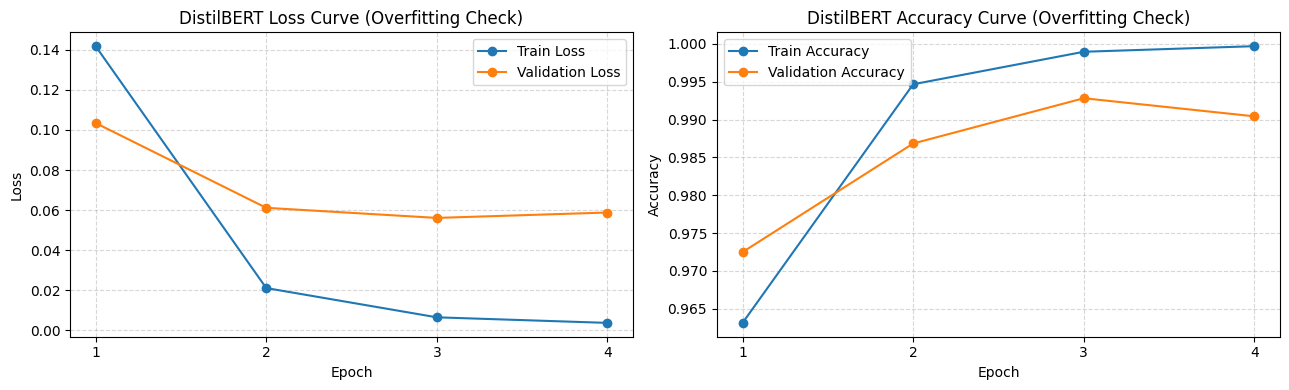

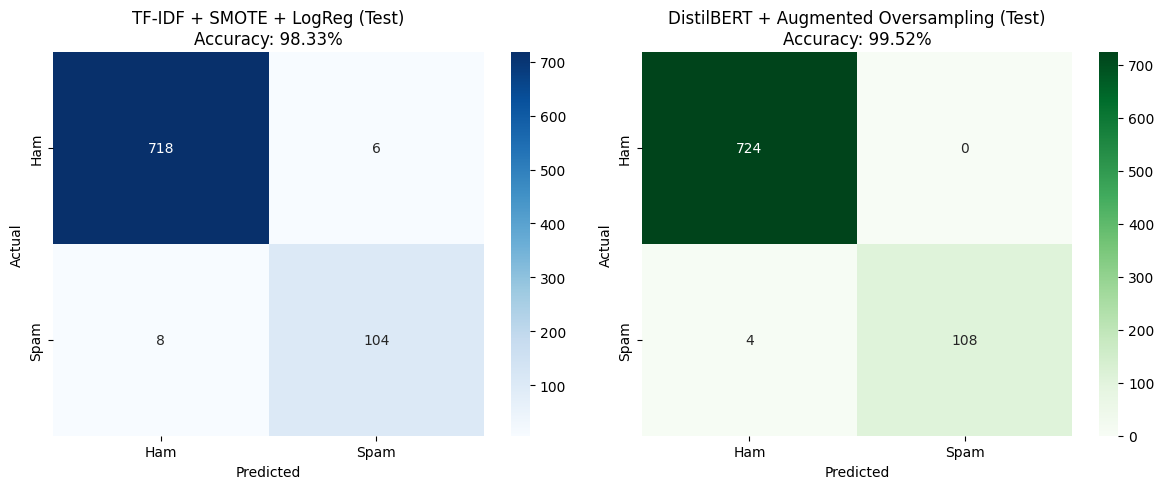

In [5]:
import time
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE, RandomOverSampler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, get_linear_schedule_with_warmup
from tqdm import tqdm

# ==========================================
# 1. Load & Clean SMS Dataset (Updated Kaggle Path)
# ==========================================
path = "/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv"
df = pd.read_csv(path, encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label"] = df["label"].map({"ham": 0, "spam": 1})

# 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    df["message"].tolist(),
    df["label"].values,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(f"Original Splits -> Train: {len(X_train)} {np.bincount(y_train)} | Val: {len(X_val)} | Test: {len(X_test)}\n")

# ==========================================
# MODEL 1: TF-IDF + SMOTE (More Data) + Logistic Regression
# ==========================================
print("=" * 65)
print("Training Model 1: TF-IDF + SMOTE Oversampling + Logistic Regression")
print("=" * 65)

start_lr = time.time()
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

# SMOTE increases Spam training samples to match Ham (no majority data dropped)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_vec, y_train)
print(f"Model 1 Training Size After SMOTE: {X_train_smote.shape[0]} rows -> Class counts: {np.bincount(y_train_smote)}")

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_smote, y_train_smote)
lr_time = time.time() - start_lr

# Overfitting Check (evaluated on real un-SMOTEd Train vs Val)
lr_train_acc = accuracy_score(y_train, lr_model.predict(X_train_vec))
lr_val_acc = accuracy_score(y_val, lr_model.predict(X_val_vec))
lr_test_preds = lr_model.predict(X_test_vec)
lr_test_acc = accuracy_score(y_test, lr_test_preds)

print(f"Time: {lr_time:.2f}s")
print(f"Overfitting Check -> Train Acc: {lr_train_acc:.4f} | Val Acc: {lr_val_acc:.4f} | Gap: {lr_train_acc - lr_val_acc:.4f}")
print(f"Final Test Accuracy: {lr_test_acc:.4f}\n")
print(classification_report(y_test, lr_test_preds, target_names=["Ham", "Spam"]))

# ==========================================
# MODEL 2: DistilBERT + Augmented Oversampling (2x T4 GPU)
# ==========================================
print("=" * 65)
print("Training Model 2: DistilBERT + Augmented Text Oversampling")
print("=" * 65)

# Oversample raw text so Spam matches Ham count (increases dataset size)
ros = RandomOverSampler(random_state=42)
X_train_df = pd.DataFrame({"text": X_train})
X_train_ros_df, y_train_ros = ros.fit_resample(X_train_df, y_train)

# Light text augmentation on oversampled Spam rows to prevent exact-duplicate memorization
random.seed(42)
def augment_spam_text(text, p_drop=0.10):
    words = text.split()
    if len(words) <= 4:
        return text
    # Randomly drop ~10% of words or swap two adjacent words
    kept = [w for w in words if random.random() > p_drop]
    if len(kept) < 3:
        kept = words
    if len(kept) > 3 and random.random() < 0.5:
        idx = random.randint(0, len(kept) - 2)
        kept[idx], kept[idx + 1] = kept[idx + 1], kept[idx]
    return " ".join(kept)

orig_train_len = len(X_train)
X_train_aug = []
for i, text in enumerate(X_train_ros_df["text"].tolist()):
    # Keep all original samples untouched; lightly augment newly oversampled Spam copies
    if i >= orig_train_len and y_train_ros[i] == 1:
        X_train_aug.append(augment_spam_text(text))
    else:
        X_train_aug.append(text)

print(f"Model 2 Training Size After Oversampling: {len(X_train_aug)} rows -> Class counts: {np.bincount(y_train_ros)}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
print(f"Using device: {device} | Available GPUs: {num_gpus}")

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
MAX_LEN = 128

train_encodings = tokenizer(X_train_aug, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
val_encodings = tokenizer(X_val, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
test_encodings = tokenizer(X_test, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")

class SMSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

batch_size = 32 * max(1, num_gpus)
train_loader = DataLoader(SMSDataset(train_encodings, y_train_ros), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(SMSDataset(val_encodings, y_val), batch_size=64 * max(1, num_gpus), shuffle=False)
test_loader = DataLoader(SMSDataset(test_encodings, y_test), batch_size=64 * max(1, num_gpus), shuffle=False)

bert_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

if num_gpus > 1:
    print(f"Wrapping DistilBERT with nn.DataParallel across {num_gpus} GPUs...")
    bert_model = nn.DataParallel(bert_model)

bert_model.to(device)

EPOCHS = 4
optimizer = AdamW(bert_model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

def evaluate_bert(model, loader):
    model.eval()
    total_loss = 0
    preds, targets = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss.mean()
            total_loss += loss.item()

            preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
            targets.extend(labels.cpu().numpy())
    return total_loss / len(loader), accuracy_score(targets, preds), preds

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start_bert = time.time()
for epoch in range(EPOCHS):
    bert_model.train()
    total_train_loss = 0
    train_preds, train_targets = [], []

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss.mean()

        loss.backward()
        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()
        train_preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader)
    train_acc = accuracy_score(train_targets, train_preds)
    val_loss, val_acc, _ = evaluate_bert(bert_model, val_loader)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} - Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}"
    )

bert_time = time.time() - start_bert

# Final Test Evaluation
_, bert_test_acc, bert_test_preds = evaluate_bert(bert_model, test_loader)
print(f"\nTotal Training Time: {bert_time:.2f}s")
print(f"Final DistilBERT Test Accuracy: {bert_test_acc:.4f}\n")
print(classification_report(y_test, bert_test_preds, target_names=["Ham", "Spam"]))

# ==========================================
# 3. Overfitting Learning Curves (DistilBERT)
# ==========================================
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("DistilBERT Loss Curve (Overfitting Check)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(epochs_range)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
axes[1].set_title("DistilBERT Accuracy Curve (Overfitting Check)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(epochs_range)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================
# 4. Side-by-Side Test Confusion Matrices
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, lr_test_preds)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[0].set_title(f"TF-IDF + SMOTE + LogReg (Test)\nAccuracy: {lr_test_acc:.2%}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_bert = confusion_matrix(y_test, bert_test_preds)
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[1].set_title(f"DistilBERT + Augmented Oversampling (Test)\nAccuracy: {bert_test_acc:.2%}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()